# First Run Analysis — VNMath-192 Pilot Study

**Checkpoint:** `checkpints20260416_vnmath192`  
**Dataset:** 192 Vietnamese school math problems  
**Models evaluated:** gemma2-9b · llama3.1-8b · qwen2.5-7b · Ternary-Bonsai-1.7B · Ternary-Bonsai-8B

This notebook loads all checkpoint JSONL files and produces:
1. Pass@1 per model
2. Partial-credit (test-pass ratio) distribution
3. Token usage & latency comparison
4. Per-task difficulty heatmap
5. Error-type breakdown
6. Code-length vs pass rate scatter

In [1]:
import json
import glob
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from collections import Counter

# ── aesthetics ──────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
COLORS = sns.color_palette('Set2', 8)
plt.rcParams.update({'figure.dpi': 130, 'figure.figsize': (10, 4)})

CHECKPOINT_DIR = Path('.')  # notebook lives in the checkpoint directory
PROBLEMS_PATH  = Path('../../problems/VNSchoolMathProblems.v0.3.json')

In [2]:
# ── Load all checkpoint files ────────────────────────────────────────────────
records = []
for path in sorted(CHECKPOINT_DIR.glob('checkpoint_*.jsonl')):
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))

df = pd.DataFrame(records)

# Derived columns
df['pass_ratio']    = df['tests_passed'] / df['tests_total'].replace(0, np.nan)
df['code_length']   = df['extracted_code'].fillna('').apply(len)
df['model_short']   = df['model'].str.replace('prism-ml-', '', regex=False)

print(f'Total records : {len(df)}')
print(f'Models        : {df["model_short"].unique().tolist()}')
print(f'Tasks         : {df["task_id"].nunique()}')
df.head(3)

Total records : 960
Models        : ['gemma2:9b', 'llama3.1:8b', 'prism-ml/Ternary-Bonsai-1.7B-mlx-2bit', 'prism-ml/Ternary-Bonsai-8B-mlx-2bit', 'qwen2.5:7b']
Tasks         : 192


,timestamp,model,task_id,run_id,passed,tests_passed,tests_total,errors,duration_seconds,prompt_tokens,completion_tokens,total_tokens,response_length,response_text,extracted_code,pass_ratio,code_length,model_short
0,2026-04-16T13:30:48.572734,gemma2:9b,1,1,False,0,7,"[Traceback (most recent call last):\n File ""/...",16.614408,176,571,747,1890,```python\nimport math\n\ndef calculate_glue_c...,"import math\n\ndef calculate_glue_cost(length,...",0.000000,960,gemma2:9b
1,2026-04-16T13:30:59.572072,gemma2:9b,2,1,False,0,7,[Test failed: assert find_min_first_payment(45...,10.895376,192,505,697,1958,"```python\ndef find_min_first_payment(debt, ta...","def find_min_first_payment(debt, target_percen...",0.000000,895,gemma2:9b
2,2026-04-16T13:31:11.735064,gemma2:9b,3,1,False,6,7,"[Test failed: assert calculate_max_reward(10, ...",12.025783,196,559,755,1895,"```python\ndef calculate_max_reward(n, s, r):\...","def calculate_max_reward(n, s, r):\n """"""Cal...",0.857143,660,gemma2:9b


In [3]:
# ── Load problem metadata ────────────────────────────────────────────────────
with open(PROBLEMS_PATH) as f:
    problems = json.load(f)

prob_df = pd.DataFrame([
    {'task_id': p['task_id'],
     'n_tests': len(p.get('test_list', [])),
     'has_challenge': bool(p.get('challenge_test_list')),
     'text_len': len(p.get('text', ''))}
    for p in problems
])
print(prob_df.head())

   task_id  n_tests  has_challenge  text_len
0        1        2           True       329
1        2        2           True       339
2        3        2           True       364
3        4        2           True       366
4        5        2           True       277


## 1 · Pass@1 per Model

,total,passed_n,pass_at_1_%,avg_ratio_%,avg_tokens,avg_secs
model_short,,,,,,
prism-ml/Ternary-Bonsai-8B-mlx-2bit,192,19,9.90,14.36,1189.98,16.49
gemma2:9b,192,17,8.85,13.17,789.11,18.05
llama3.1:8b,192,15,7.81,9.60,575.08,12.08
qwen2.5:7b,192,13,6.77,9.00,521.81,8.74
prism-ml/Ternary-Bonsai-1.7B-mlx-2bit,192,3,1.56,2.53,1376.01,6.42


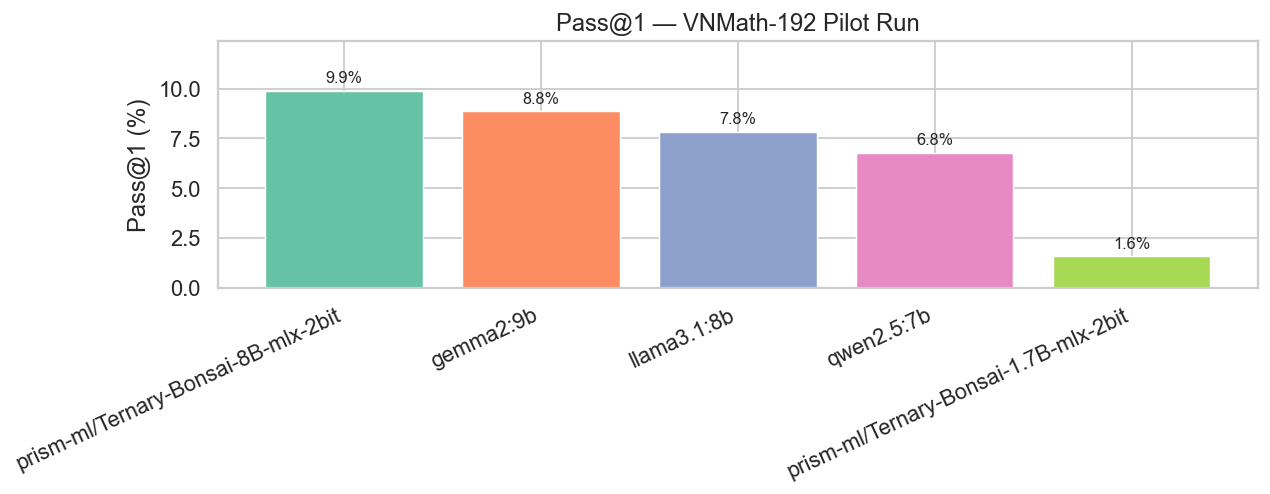

In [4]:
summary = (
    df.groupby('model_short')
      .agg(
          total      = ('passed', 'count'),
          passed_n   = ('passed', 'sum'),
          pass_at_1  = ('passed', 'mean'),
          avg_ratio  = ('pass_ratio', 'mean'),
          avg_tokens = ('total_tokens', 'mean'),
          avg_secs   = ('duration_seconds', 'mean'),
      )
      .sort_values('pass_at_1', ascending=False)
)
summary['pass_at_1_%'] = (summary['pass_at_1'] * 100).round(2)
summary['avg_ratio_%'] = (summary['avg_ratio'] * 100).round(2)
display(summary[['total','passed_n','pass_at_1_%','avg_ratio_%','avg_tokens','avg_secs']].round(2))

fig, ax = plt.subplots()
bars = ax.bar(summary.index, summary['pass_at_1_%'], color=COLORS[:len(summary)], edgecolor='white', linewidth=0.8)
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_ylabel('Pass@1 (%)')
ax.set_title('Pass@1 — VNMath-192 Pilot Run')
ax.set_ylim(0, max(summary['pass_at_1_%']) * 1.25)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('fig_pass_at_1.png', bbox_inches='tight')
plt.show()

## 2 · Partial-Credit Distribution (test-pass ratio)

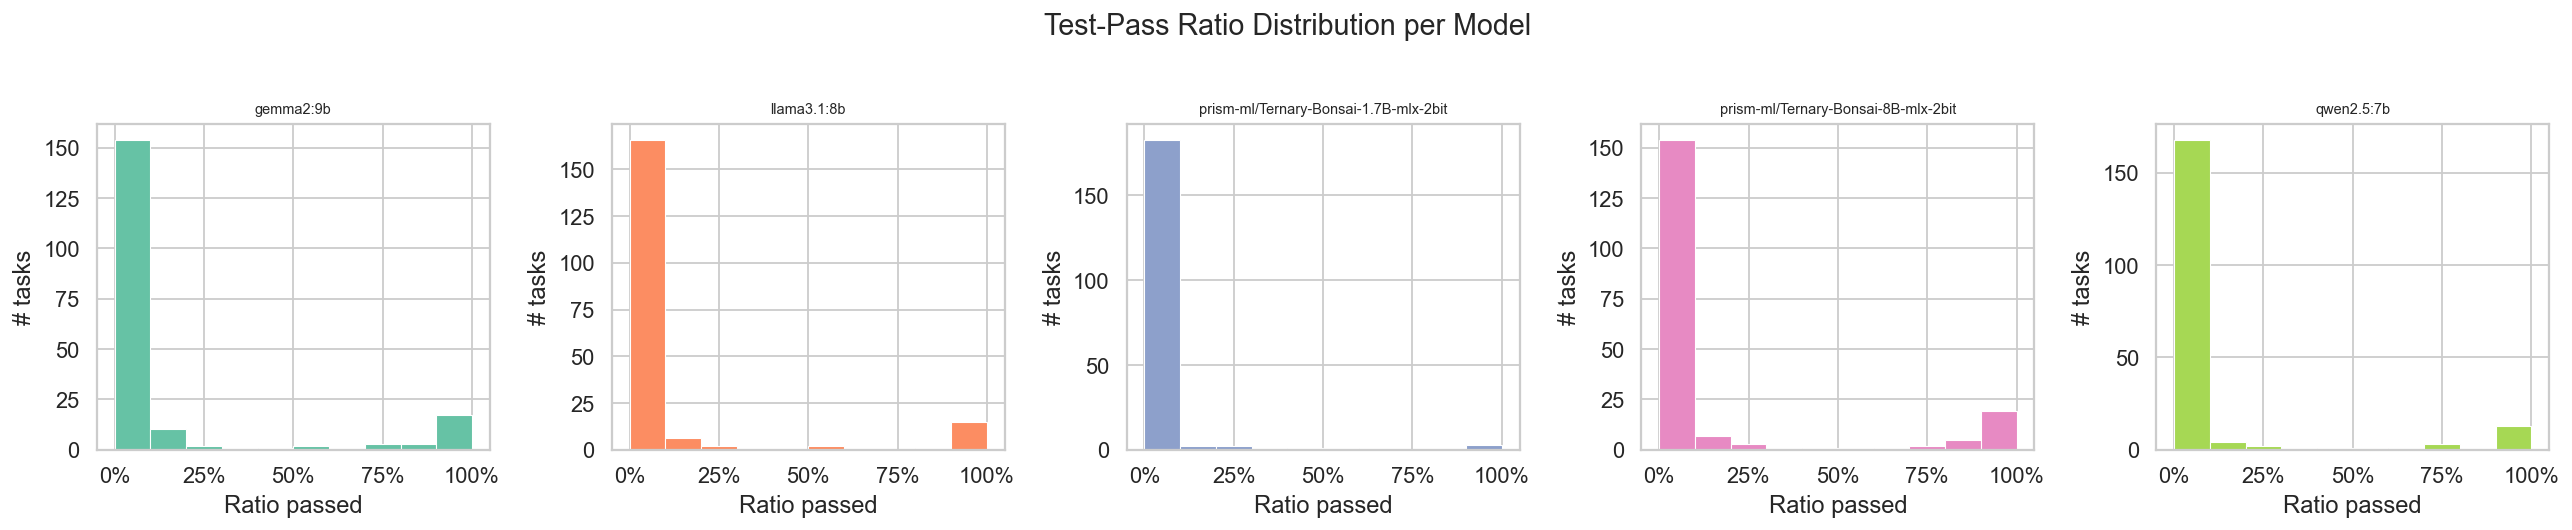

In [5]:
models = df['model_short'].unique()
n = len(models)
fig, axes = plt.subplots(1, n, figsize=(4*n, 4), sharey=False)
if n == 1:
    axes = [axes]

for ax, (model, grp) in zip(axes, df.groupby('model_short')):
    bins = np.linspace(0, 1, 11)
    ax.hist(grp['pass_ratio'].dropna(), bins=bins, color=COLORS[list(models).index(model)],
            edgecolor='white', linewidth=0.6)
    ax.set_title(model, fontsize=8)
    ax.set_xlabel('Ratio passed')
    ax.set_ylabel('# tasks')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))

fig.suptitle('Test-Pass Ratio Distribution per Model', y=1.02)
plt.tight_layout()
plt.savefig('fig_ratio_dist.png', bbox_inches='tight')
plt.show()

## 3 · Token Usage & Latency

/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_48540/982274902.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_short', y=col, order=order,
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_48540/982274902.py:14: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', fontsize=7)
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_48540/982274902.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_short', y=col, order=order,
/var/folders/zh/g_gf_j_s13l4g_rmzlh9125w0000gn/T/ipykernel_48540/982274902.py:14: UserWarning: FixedFormatter shoul

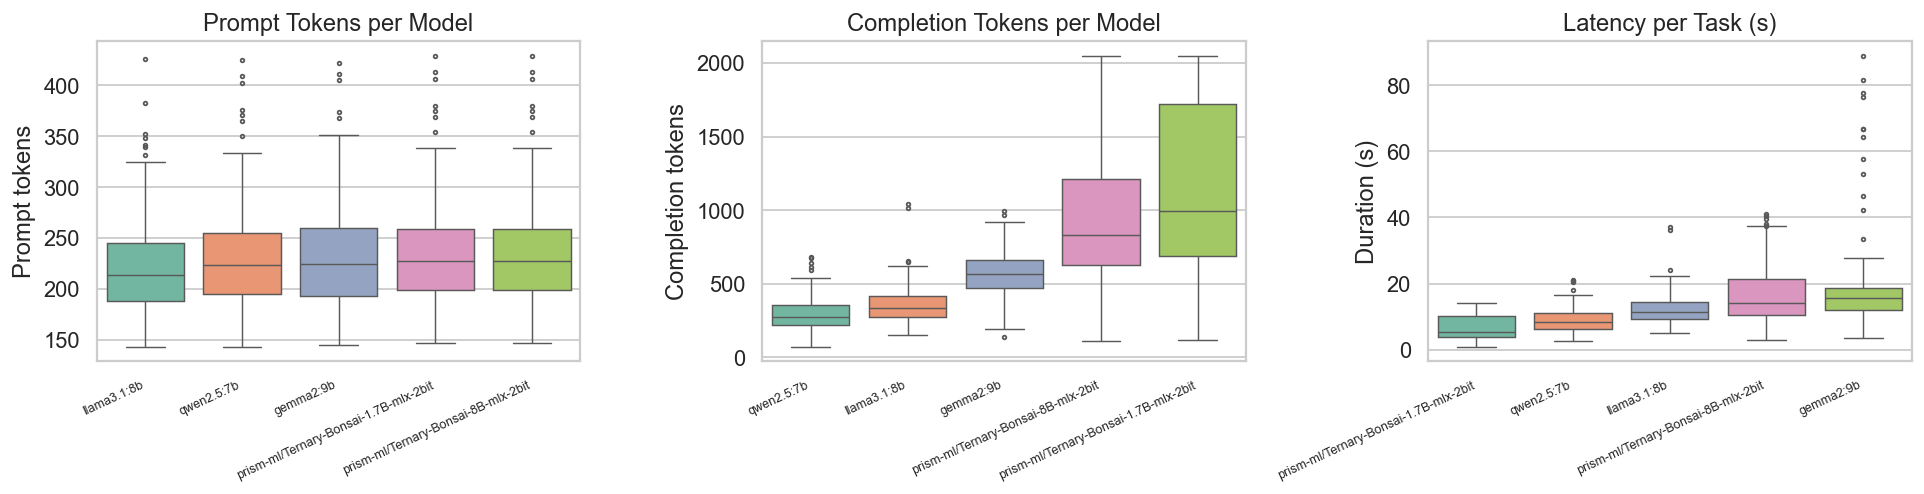

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

token_cols = ['prompt_tokens', 'completion_tokens', 'duration_seconds']
ylabels    = ['Prompt tokens', 'Completion tokens', 'Duration (s)']
titles     = ['Prompt Tokens per Model', 'Completion Tokens per Model', 'Latency per Task (s)']

for ax, col, ylabel, title in zip(axes, token_cols, ylabels, titles):
    order = df.groupby('model_short')[col].median().sort_values().index
    sns.boxplot(data=df, x='model_short', y=col, order=order,
                palette='Set2', ax=ax, fliersize=2, linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', fontsize=7)

plt.tight_layout()
plt.savefig('fig_tokens_latency.png', bbox_inches='tight')
plt.show()

## 4 · Per-Task Difficulty Heatmap

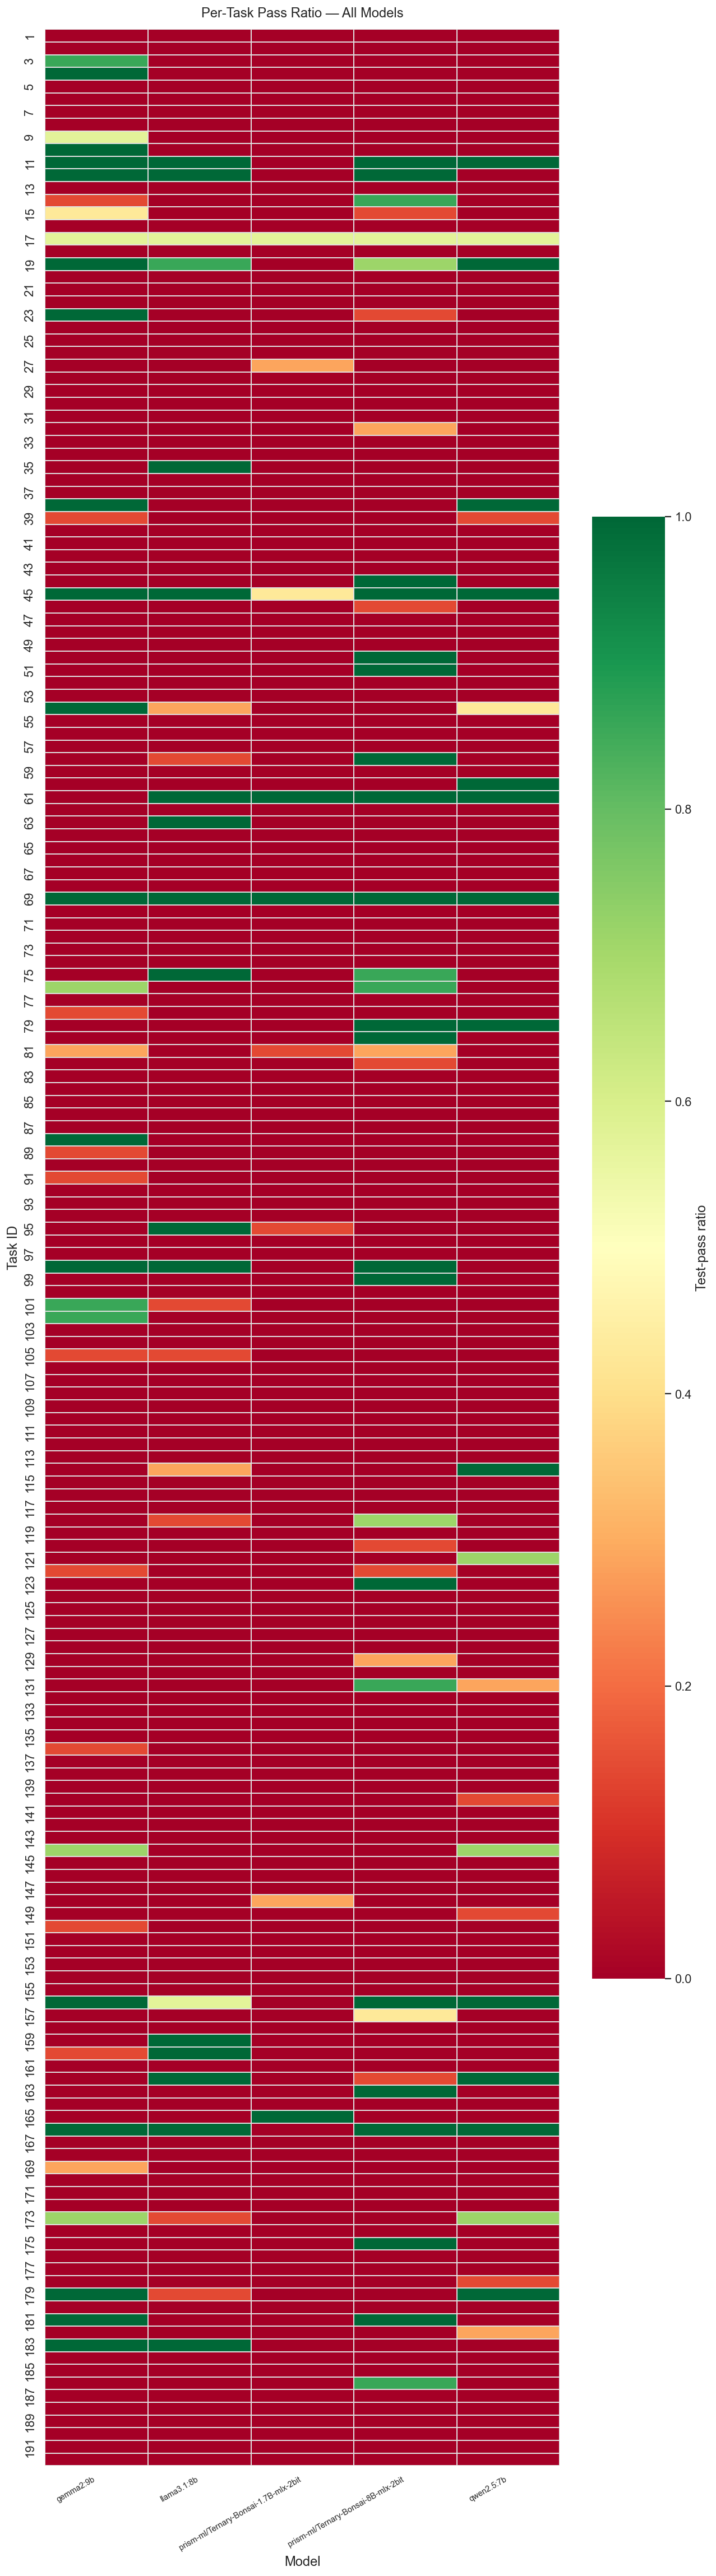

Tasks no model solved (118): [1, 2, 5, 6, 7, 8, 13, 16, 18, 20, 21, 22, 24, 25, 26, 28, 29, 30, 31, 33]


In [7]:
pivot = df.pivot_table(index='task_id', columns='model_short', values='pass_ratio', aggfunc='mean')
pivot = pivot.sort_index()

fig, ax = plt.subplots(figsize=(len(pivot.columns)*2, min(len(pivot)*0.18 + 1, 40)))
sns.heatmap(
    pivot, ax=ax, cmap='RdYlGn', vmin=0, vmax=1,
    linewidths=0.1, linecolor='#e0e0e0',
    cbar_kws={'label': 'Test-pass ratio', 'shrink': 0.6}
)
ax.set_title('Per-Task Pass Ratio — All Models', pad=12)
ax.set_xlabel('Model')
ax.set_ylabel('Task ID')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=8)
plt.tight_layout()
plt.savefig('fig_heatmap.png', bbox_inches='tight')
plt.show()

# Tasks no model solved
never_solved = pivot[pivot.max(axis=1) == 0].index.tolist()
print(f'Tasks no model solved ({len(never_solved)}): {never_solved[:20]}')

## 5 · Error-Type Breakdown

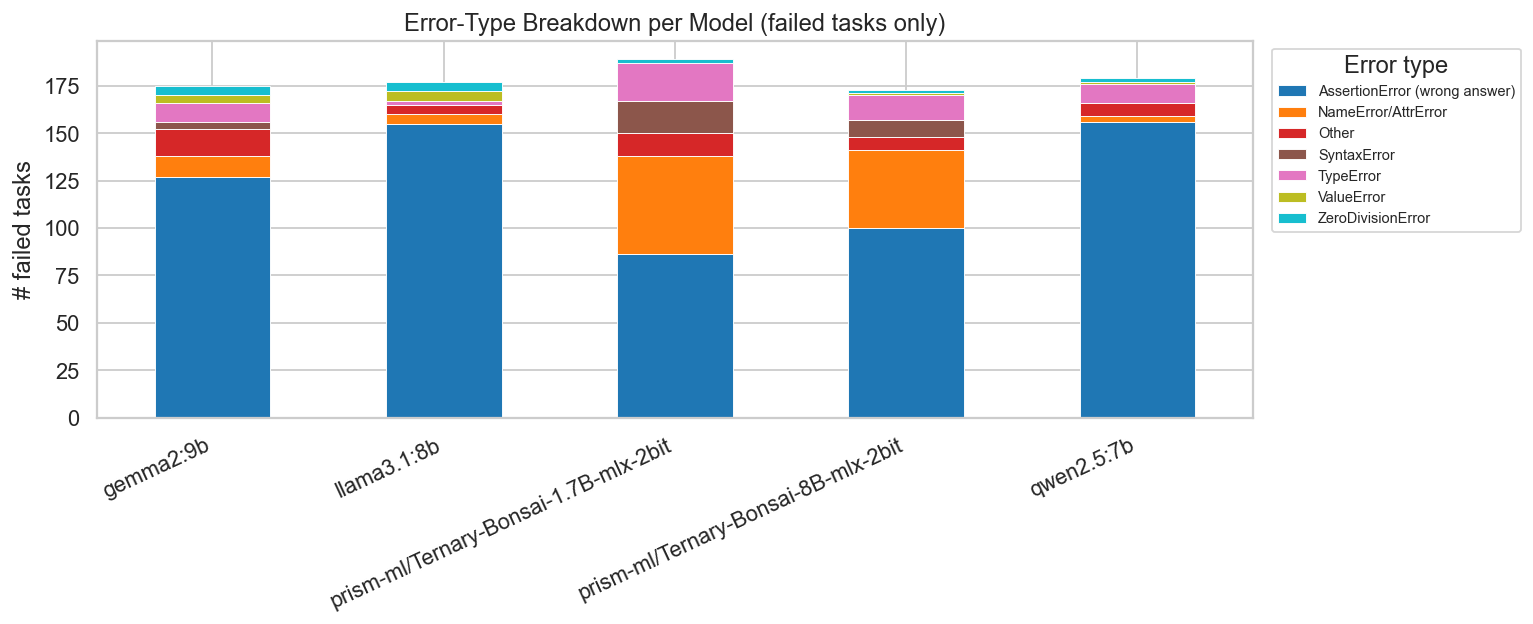

In [8]:
def classify_error(err_list):
    """Return dominant error type from a list of error strings."""
    joined = ' '.join(err_list)
    if not joined:
        return 'No error'
    if 'SyntaxError' in joined or 'IndentationError' in joined:
        return 'SyntaxError'
    if 'ZeroDivisionError' in joined:
        return 'ZeroDivisionError'
    if 'TypeError' in joined:
        return 'TypeError'
    if 'ValueError' in joined:
        return 'ValueError'
    if 'NameError' in joined or 'AttributeError' in joined:
        return 'NameError/AttrError'
    if 'TimeoutError' in joined or 'Timeout' in joined:
        return 'Timeout'
    if 'AssertionError' in joined:
        return 'AssertionError (wrong answer)'
    return 'Other'

df['error_type'] = df['errors'].apply(lambda e: classify_error(e) if isinstance(e, list) else 'No error')

err_pivot = (
    df[df['passed'] == False]
      .groupby(['model_short', 'error_type'])
      .size()
      .unstack(fill_value=0)
)

err_pivot.plot(kind='bar', stacked=True, colormap='tab10', figsize=(12, 5),
               edgecolor='white', linewidth=0.5)
plt.title('Error-Type Breakdown per Model (failed tasks only)')
plt.xlabel('')
plt.ylabel('# failed tasks')
plt.xticks(rotation=25, ha='right')
plt.legend(title='Error type', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('fig_errors.png', bbox_inches='tight')
plt.show()

## 6 · Code Length vs Pass Rate

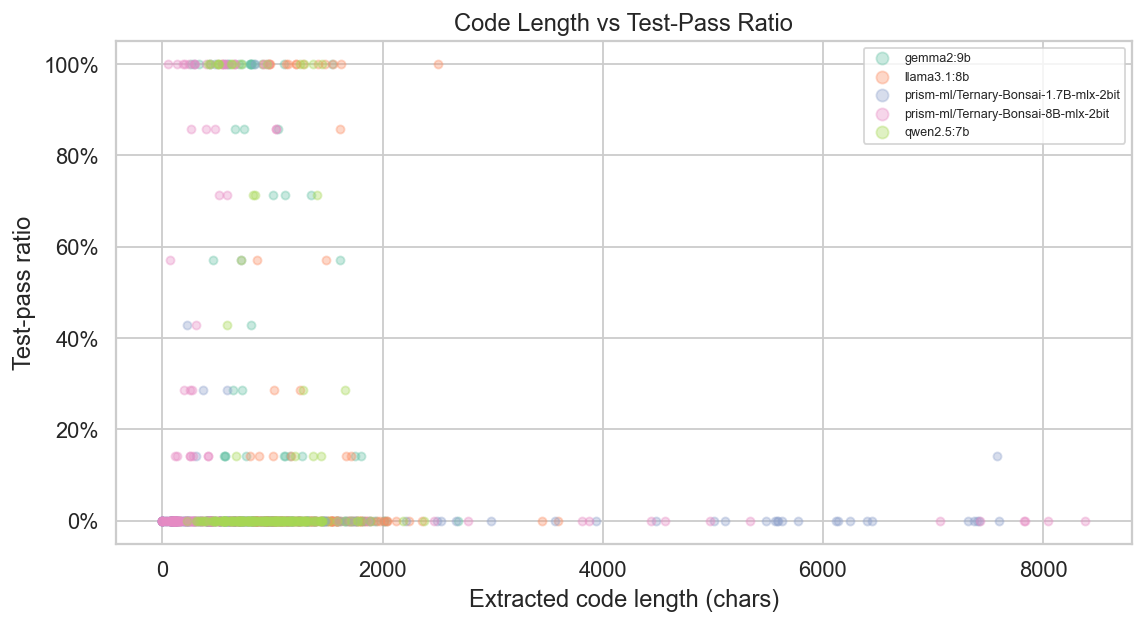

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for i, (model, grp) in enumerate(df.groupby('model_short')):
    ax.scatter(
        grp['code_length'], grp['pass_ratio'],
        alpha=0.35, s=20, color=COLORS[i], label=model
    )
ax.set_xlabel('Extracted code length (chars)')
ax.set_ylabel('Test-pass ratio')
ax.set_title('Code Length vs Test-Pass Ratio')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(fontsize=7, markerscale=1.5)
plt.tight_layout()
plt.savefig('fig_code_length_scatter.png', bbox_inches='tight')
plt.show()

## 7 · Consensus Analysis — Tasks All Models Solved / None Solved

All models passed  :   1 tasks  [69]
No model passed    : 154 tasks  [1, 2, 3, 5, 6, 7, 8, 9, 13, 14]
Partially solved   :  37 tasks


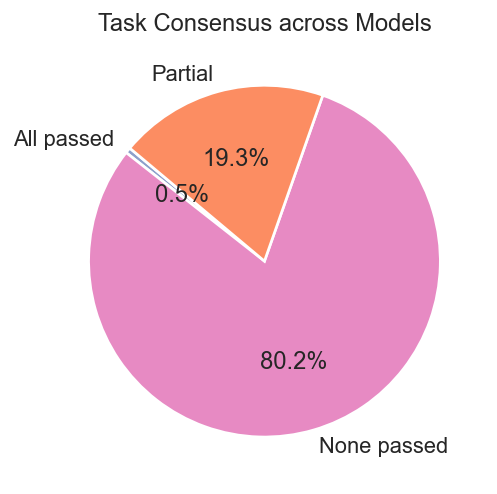

In [10]:
pass_pivot = df.pivot_table(index='task_id', columns='model_short', values='passed', aggfunc='max')
pass_pivot = pass_pivot.fillna(False).astype(bool)

all_pass   = pass_pivot[pass_pivot.all(axis=1)].index.tolist()
none_pass  = pass_pivot[~pass_pivot.any(axis=1)].index.tolist()
some_pass  = pass_pivot[(pass_pivot.any(axis=1)) & (~pass_pivot.all(axis=1))].index.tolist()

print(f'All models passed  : {len(all_pass):3d} tasks  {all_pass[:10]}')
print(f'No model passed    : {len(none_pass):3d} tasks  {none_pass[:10]}')
print(f'Partially solved   : {len(some_pass):3d} tasks')

fig, ax = plt.subplots(figsize=(5, 4))
labels  = ['All passed', 'None passed', 'Partial']
counts  = [len(all_pass), len(none_pass), len(some_pass)]
wedges, texts, autotexts = ax.pie(
    counts, labels=labels, autopct='%1.1f%%',
    colors=[COLORS[2], COLORS[3], COLORS[1]], startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
ax.set_title('Task Consensus across Models')
plt.tight_layout()
plt.savefig('fig_consensus.png', bbox_inches='tight')
plt.show()

## 8 · Summary Table

In [11]:
final = summary[['passed_n','pass_at_1_%','avg_ratio_%','avg_tokens','avg_secs']].copy()
final.columns = ['Tasks Passed', 'Pass@1 (%)', 'Avg Test-Pass Ratio (%)', 'Avg Tokens', 'Avg Latency (s)']
final = final.round(2)
display(final.style
    .background_gradient(subset=['Pass@1 (%)'], cmap='YlGn')
    .background_gradient(subset=['Avg Tokens'], cmap='YlOrRd_r')
    .format({'Pass@1 (%)': '{:.2f}%', 'Avg Test-Pass Ratio (%)': '{:.2f}%',
             'Avg Tokens': '{:.0f}', 'Avg Latency (s)': '{:.2f}s'})
)

,Tasks Passed,Pass@1 (%),Avg Test-Pass Ratio (%),Avg Tokens,Avg Latency (s)
model_short,,,,,
prism-ml/Ternary-Bonsai-8B-mlx-2bit,19,9.90%,14.36%,1190,16.49s
gemma2:9b,17,8.85%,13.17%,789,18.05s
llama3.1:8b,15,7.81%,9.60%,575,12.08s
qwen2.5:7b,13,6.77%,9.00%,522,8.74s
prism-ml/Ternary-Bonsai-1.7B-mlx-2bit,3,1.56%,2.53%,1376,6.42s
